# Exploratory Data Analysis Starter

## Import packages

In [1]:
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Shows plots in jupyter notebook
%matplotlib inline

# Set plot style
sns.set(color_codes=True)

---

## Loading data with Pandas

We need to load `client_data.csv` and `price_data.csv` into individual dataframes so that we can work with them in Python. For this notebook and all further notebooks, it will be assumed that the CSV files will the placed in the same file location as the notebook. If they are not, please adjust the directory within the `read_csv` method accordingly.

In [2]:
client_df = pd.read_csv('./client_data.csv')
price_df = pd.read_csv('./price_data.csv')

You can view the first 3 rows of a dataframe using the `head` method. Similarly, if you wanted to see the last 3, you can use `tail(3)`

In [3]:
client_df.head(3)

,id,channel_sales,cons_12m,cons_gas_12m,cons_last_month,date_activ,date_end,date_modif_prod,date_renewal,forecast_cons_12m,...,has_gas,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,origin_up,pow_max,churn
0,24011ae4ebbe3035111d65fa7c15bc57,foosdfpfkusacimwkcsosbicdxkicaua,0,54946,0,2013-06-15,2016-06-15,2015-11-01,2015-06-23,0.00,...,t,0.0,25.44,25.44,2,678.99,3,lxidpiddsbxsbosboudacockeimpuepw,43.648,1
1,d29c2c54acc38ff3c0614d0a653813dd,MISSING,4660,0,0,2009-08-21,2016-08-30,2009-08-21,2015-08-31,189.95,...,f,0.0,16.38,16.38,1,18.89,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.800,0
2,764c75f661154dac3a6c254cd082ea7d,foosdfpfkusacimwkcsosbicdxkicaua,544,0,0,2010-04-16,2016-04-16,2010-04-16,2015-04-17,47.96,...,f,0.0,28.60,28.60,1,6.60,6,kamkkxfxxuwbdslkwifmmcsiusiuosws,13.856,0


In [4]:
price_df.head(3)

,id,price_date,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
0,038af19179925da21a25619c5a24b745,2015-01-01,0.151367,0.0,0.0,44.266931,0.0,0.0
1,038af19179925da21a25619c5a24b745,2015-02-01,0.151367,0.0,0.0,44.266931,0.0,0.0
2,038af19179925da21a25619c5a24b745,2015-03-01,0.151367,0.0,0.0,44.266931,0.0,0.0


---

## Descriptive statistics of data

### Data types

It is useful to first understand the data that you're dealing with along with the data types of each column. The data types may dictate how you transform and engineer features.

To get an overview of the data types within a data frame, use the `info()` method.

In [5]:
client_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 14606 entries, 0 to 14605
Data columns (total 26 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id                        14606 non-null  object 
 1   channel_sales             14606 non-null  object 
 2   cons_12m                  14606 non-null  int64  
 3   cons_gas_12m              14606 non-null  int64  
 4   cons_last_month           14606 non-null  int64  
 5   date_activ                14606 non-null  object 
 6   date_end                  14606 non-null  object 
 7   date_modif_prod           14606 non-null  object 
 8   date_renewal              14606 non-null  object 
 9   forecast_cons_12m         14606 non-null  float64
 10  forecast_cons_year        14606 non-null  int64  
 11  forecast_discount_energy  14606 non-null  float64
 12  forecast_meter_rent_12m   14606 non-null  float64
 13  forecast_price_energy_p1  14606 non-null  float64
 14  foreca

In [6]:
price_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 193002 entries, 0 to 193001
Data columns (total 8 columns):
 #   Column              Non-Null Count   Dtype  
---  ------              --------------   -----  
 0   id                  193002 non-null  object 
 1   price_date          193002 non-null  object 
 2   price_off_peak_var  193002 non-null  float64
 3   price_peak_var      193002 non-null  float64
 4   price_mid_peak_var  193002 non-null  float64
 5   price_off_peak_fix  193002 non-null  float64
 6   price_peak_fix      193002 non-null  float64
 7   price_mid_peak_fix  193002 non-null  float64
dtypes: float64(6), object(2)
memory usage: 11.8+ MB


### Statistics

Now let's look at some statistics about the datasets. We can do this by using the `describe()` method.

In [7]:
client_df.describe()

,cons_12m,cons_gas_12m,cons_last_month,forecast_cons_12m,forecast_cons_year,forecast_discount_energy,forecast_meter_rent_12m,forecast_price_energy_p1,forecast_price_energy_p2,forecast_price_pow_p1,imp_cons,margin_gross_pow_ele,margin_net_pow_ele,nb_prod_act,net_margin,num_years_antig,pow_max,churn
count,1.460600e+04,1.460600e+04,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000,14606.000000
mean,1.592203e+05,2.809238e+04,16090.269752,1868.614880,1399.762906,0.966726,63.086871,0.137283,0.050491,43.130056,152.786896,24.565121,24.562517,1.292346,189.264522,4.997809,18.135136,0.097152
std,5.734653e+05,1.629731e+05,64364.196422,2387.571531,3247.786255,5.108289,66.165783,0.024623,0.049037,4.485988,341.369366,20.231172,20.230280,0.709774,311.798130,1.611749,13.534743,0.296175
min,0.000000e+00,0.000000e+00,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.000000,1.000000,3.300000,0.000000
25%,5.674750e+03,0.000000e+00,0.000000,494.995000,0.000000,0.000000,16.180000,0.116340,0.000000,40.606701,0.000000,14.280000,14.280000,1.000000,50.712500,4.000000,12.500000,0.000000
50%,1.411550e+04,0.000000e+00,792.500000,1112.875000,314.000000,0.000000,18.795000,0.143166,0.084138,44.311378,37.395000,21.640000,21.640000,1.000000,112.530000,5.000000,13.856000,0.000000
75%,4.076375e+04,0.000000e+00,3383.000000,2401.790000,1745.750000,0.000000,131.030000,0.146348,0.098837,44.311378,193.980000,29.880000,29.880000,1.000000,243.097500,6.000000,19.172500,0.000000
max,6.207104e+06,4.154590e+06,771203.000000,82902.830000,175375.000000,30.000000,599.310000,0.273963,0.195975,59.266378,15042.790000,374.640000,374.640000,32.000000,24570.650000,13.000000,320.000000,1.000000


In [8]:
price_df.describe()

,price_off_peak_var,price_peak_var,price_mid_peak_var,price_off_peak_fix,price_peak_fix,price_mid_peak_fix
count,193002.000000,193002.000000,193002.000000,193002.000000,193002.000000,193002.000000
mean,0.141027,0.054630,0.030496,43.334477,10.622875,6.409984
std,0.025032,0.049924,0.036298,5.410297,12.841895,7.773592
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,0.125976,0.000000,0.000000,40.728885,0.000000,0.000000
50%,0.146033,0.085483,0.000000,44.266930,0.000000,0.000000
75%,0.151635,0.101673,0.072558,44.444710,24.339581,16.226389
max,0.280700,0.229788,0.114102,59.444710,36.490692,17.458221


---

## Data visualization

If you're working in Python, two of the most popular packages for visualization are `matplotlib` and `seaborn`. We highly recommend you use these, or at least be familiar with them because they are ubiquitous!

Below are some functions that you can use to get started with visualizations. 

In [9]:
def plot_stacked_bars(dataframe, title_, size_=(18, 10), rot_=0, legend_="upper right"):
    """
    Plot stacked bars with annotations
    """
    ax = dataframe.plot(
        kind="bar",
        stacked=True,
        figsize=size_,
        rot=rot_,
        title=title_
    )

    # Annotate bars
    annotate_stacked_bars(ax, textsize=14)
    # Rename legend
    plt.legend(["Retention", "Churn"], loc=legend_)
    # Labels
    plt.ylabel("Company base (%)")
    plt.show()

def annotate_stacked_bars(ax, pad=0.99, colour="white", textsize=13):
    """
    Add value annotations to the bars
    """

    # Iterate over the plotted rectanges/bars
    for p in ax.patches:
        
        # Calculate annotation
        value = str(round(p.get_height(),1))
        # If value is 0 do not annotate
        if value == '0.0':
            continue
        ax.annotate(
            value,
            ((p.get_x()+ p.get_width()/2)*pad-0.05, (p.get_y()+p.get_height()/2)*pad),
            color=colour,
            size=textsize
        )

def plot_distribution(dataframe, column, ax, bins_=50):
    """
    Plot variable distirbution in a stacked histogram of churned or retained company
    """
    # Create a temporal dataframe with the data to be plot
    temp = pd.DataFrame({"Retention": dataframe[dataframe["churn"]==0][column],
    "Churn":dataframe[dataframe["churn"]==1][column]})
    # Plot the histogram
    temp[["Retention","Churn"]].plot(kind='hist', bins=bins_, ax=ax, stacked=True)
    # X-axis label
    ax.set_xlabel(column)
    # Change the x-axis to plain style
    ax.ticklabel_format(style='plain', axis='x')

Thhe first function `plot_stacked_bars` is used to plot a stacked bar chart. An example of how you could use this is shown below:

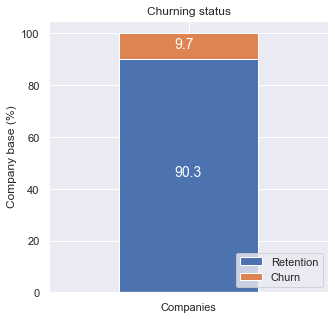

In [10]:
churn = client_df[['id', 'churn']]
churn.columns = ['Companies', 'churn']
churn_total = churn.groupby(churn['churn']).count()
churn_percentage = churn_total / churn_total.sum() * 100
plot_stacked_bars(churn_percentage.transpose(), "Churning status", (5, 5), legend_="lower right")

The second function `annotate_bars` is used by the first function, but the third function `plot_distribution` helps you to plot the distribution of a numeric column. An example of how it can be used is given below:

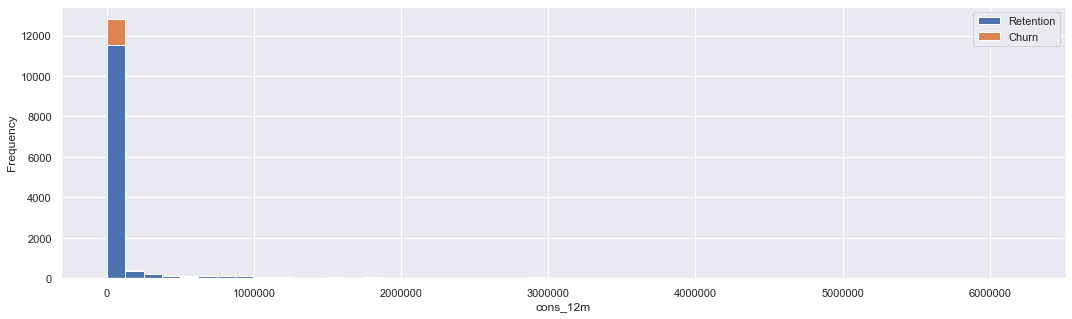

In [11]:
consumption = client_df[['id', 'cons_12m', 'cons_gas_12m', 'cons_last_month', 'imp_cons', 'has_gas', 'churn']]

fig, axs = plt.subplots(nrows=1, figsize=(18, 5))

plot_distribution(consumption, 'cons_12m', axs)

---
## 1. Deep-Dive Descriptive Statistics: Medians, Skewness & Unique Counts
Because energy consumption and financial margin metrics are often heavily right-skewed due to large industrial clients, we inspect the **median (50%)**, **standard deviation**, **skewness**, and **unique value counts** alongside the mean.

In [12]:
# Check missing values and unique counts across both datasets
print('Missing values in client_df:', client_df.isnull().sum().sum())
print('Missing values in price_df:', price_df.isnull().sum().sum())
print('\nUnique values per column in client_df:')
print(client_df.nunique())
print('\nUnique values per column in price_df:')
print(price_df.nunique())

Missing values in client_df: 0
Missing values in price_df: 0

Unique values per column in client_df:
id                                14606
channel_sales                         8
cons_12m                          11065
cons_gas_12m                       2112
cons_last_month                    4751
date_activ                         1796
date_end                            368
date_modif_prod                    2129
date_renewal                        386
forecast_cons_12m                 13993
forecast_cons_year                 4218
forecast_discount_energy             12
forecast_meter_rent_12m            3528
forecast_price_energy_off_peak      516
forecast_price_energy_peak          329
forecast_price_pow_off_peak          41
has_gas                               2
imp_cons                           7752
margin_gross_pow_ele               2391
margin_net_pow_ele                 2391
nb_prod_act                          10
net_margin                        11965
num_years_antig    

### Key Observations on Data Types & Summary Statistics:
- **Date Columns Stored as `object` Strings:** In `client_df`, `date_activ`, `date_end`, `date_modif_prod`, and `date_renewal` are stored as `object` strings, as is `price_date` in `price_df`. These must be converted to `datetime64` during feature engineering.
- **Placeholder `'MISSING'` Strings in Categorical Columns:** While `.isnull().sum()` shows 0 nulls, `channel_sales` has **3,725** records (`25.5%`) encoded as `'MISSING'`, and `origin_up` has **64** records encoded as `'MISSING'`.
- **Overall Churn Rate:** Out of `14,606` client companies, **1,419 (`9.72%`)** churned over the next 3 months while **13,187 (`90.28%`)** were retained.
- **Extreme Positive Skewness in Consumption & Margins:** `cons_12m` has a mean of `159,220.29` vs. a median of `14,115.50` ($\text{skew} = 6.00$), and `net_margin` has a mean of `189.26` vs. a median of `112.53` ($\text{skew} = 36.57$). Log-transformations or tree-based models (e.g., Random Forest) will be needed to handle these heavy tails.

---
## 2. Visualizing Categorical & Segment Variables vs. Churn
Below we analyze how churn varies across dual-fuel status (`has_gas`), sales channel (`channel_sales`), initial campaign (`origin_up`), and client tenure (`num_years_antig`).

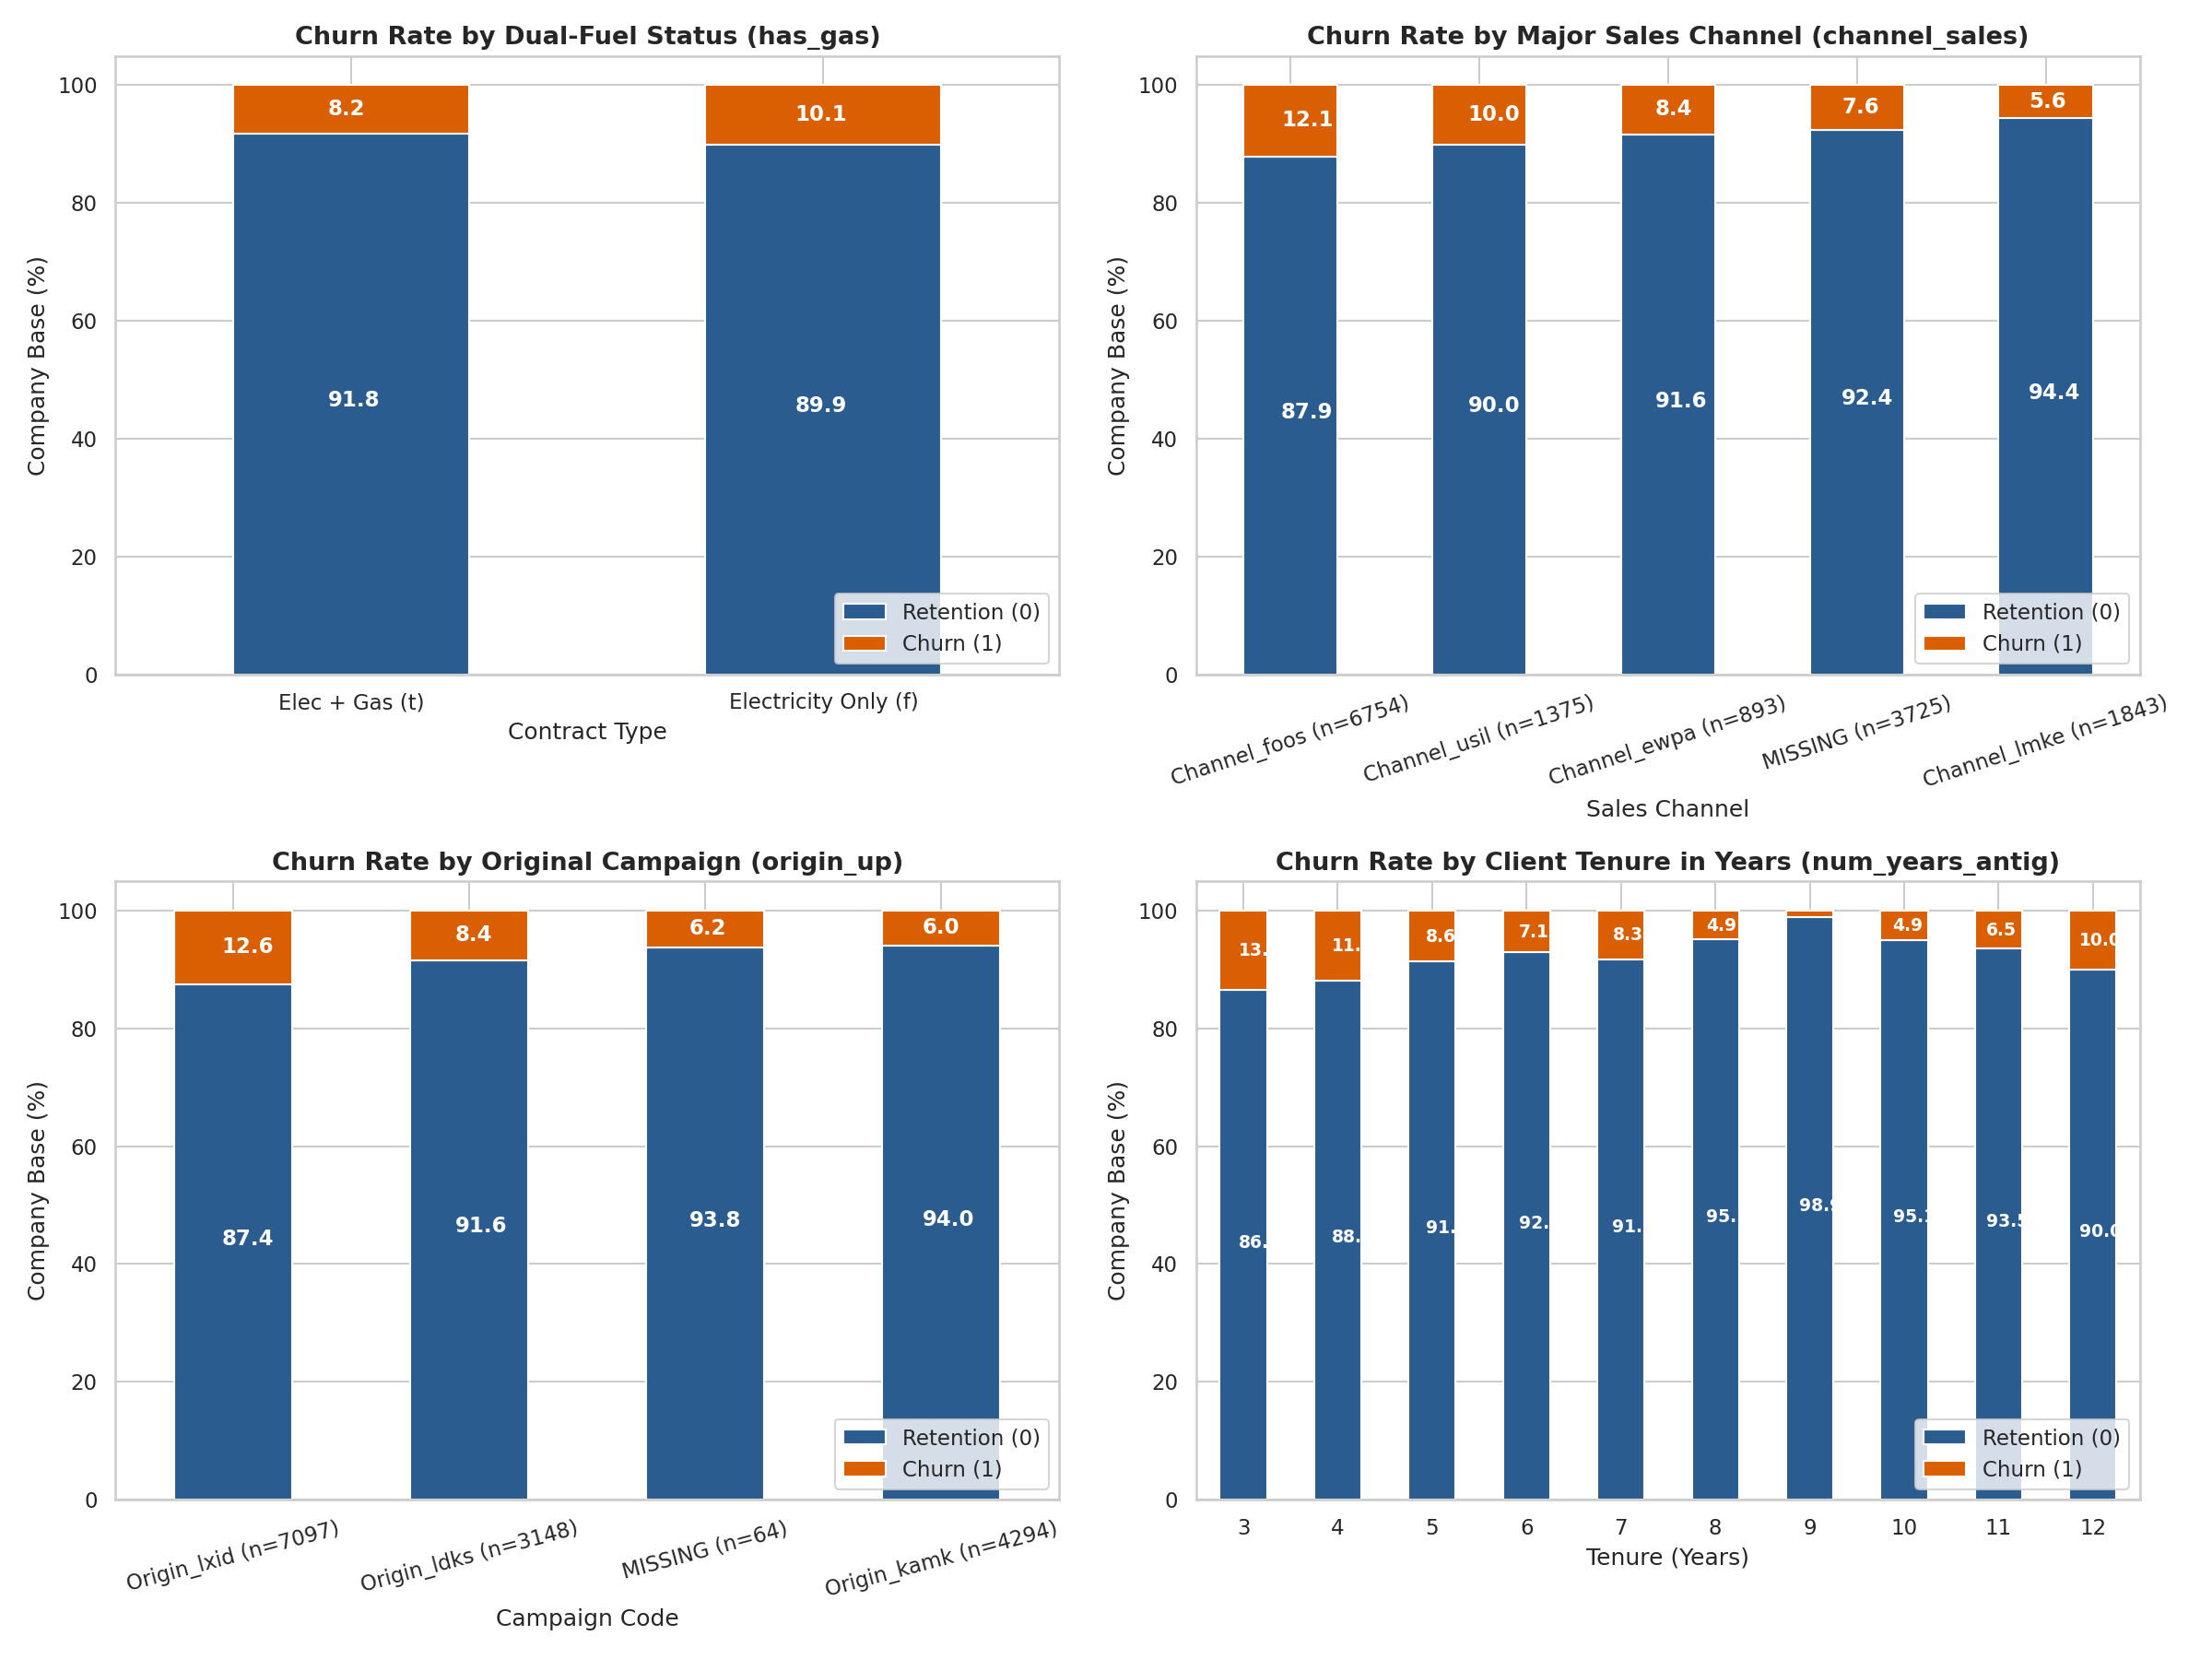

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(16, 12))

# 1. Dual-Fuel Status (has_gas)
gas_churn = pd.crosstab(client_df['has_gas'].replace({'f': 'Electricity Only (f)', 't': 'Elec + Gas (t)'}),
                        client_df['churn'], normalize='index') * 100
gas_churn.plot(kind='bar', stacked=True, ax=axes[0, 0], color=['#2b5c8f', '#d95f02'], rot=0)
annotate_stacked_bars(axes[0, 0], textsize=11)
axes[0, 0].set_title('Churn Rate by Dual-Fuel Status (has_gas)', fontsize=13, fontweight='bold')
axes[0, 0].set_ylabel('Company Base (%)')
axes[0, 0].legend(['Retention (0)', 'Churn (1)'], loc='lower right')

# 2. Major Sales Channels (channel_sales)
top_channels = client_df['channel_sales'].value_counts()[lambda x: x > 20].index
chan_df = client_df[client_df['channel_sales'].isin(top_channels)].copy()
chan_churn = pd.crosstab(chan_df['channel_sales'], chan_df['churn'], normalize='index') * 100
chan_churn.sort_values(by=1, ascending=False).plot(kind='bar', stacked=True, ax=axes[0, 1], color=['#2b5c8f', '#d95f02'], rot=18)
annotate_stacked_bars(axes[0, 1], textsize=11)
axes[0, 1].set_title('Churn Rate by Major Sales Channel', fontsize=13, fontweight='bold')

# 3. Original Campaign (origin_up)
top_origins = client_df['origin_up'].value_counts()[lambda x: x > 20].index
orig_df = client_df[client_df['origin_up'].isin(top_origins)].copy()
orig_churn = pd.crosstab(orig_df['origin_up'], orig_df['churn'], normalize='index') * 100
orig_churn.sort_values(by=1, ascending=False).plot(kind='bar', stacked=True, ax=axes[1, 0], color=['#2b5c8f', '#d95f02'], rot=15)
annotate_stacked_bars(axes[1, 0], textsize=11)
axes[1, 0].set_title('Churn Rate by Original Campaign (origin_up)', fontsize=13, fontweight='bold')

# 4. Client Tenure in Years (num_years_antig)
antig_df = client_df[client_df['num_years_antig'].between(3, 12)]
antig_churn = pd.crosstab(antig_df['num_years_antig'], antig_df['churn'], normalize='index') * 100
antig_churn.plot(kind='bar', stacked=True, ax=axes[1, 1], color=['#2b5c8f', '#d95f02'], rot=0)
annotate_stacked_bars(axes[1, 1], textsize=9)
axes[1, 1].set_title('Churn Rate by Client Tenure (num_years_antig)', fontsize=13, fontweight='bold')

plt.tight_layout()
plt.show()

---
## 3. Consumption Distributions & Outlier Inspection
We plot stacked histograms and boxplots for `cons_12m`, `cons_gas_12m`, `cons_last_month`, and `imp_cons`.

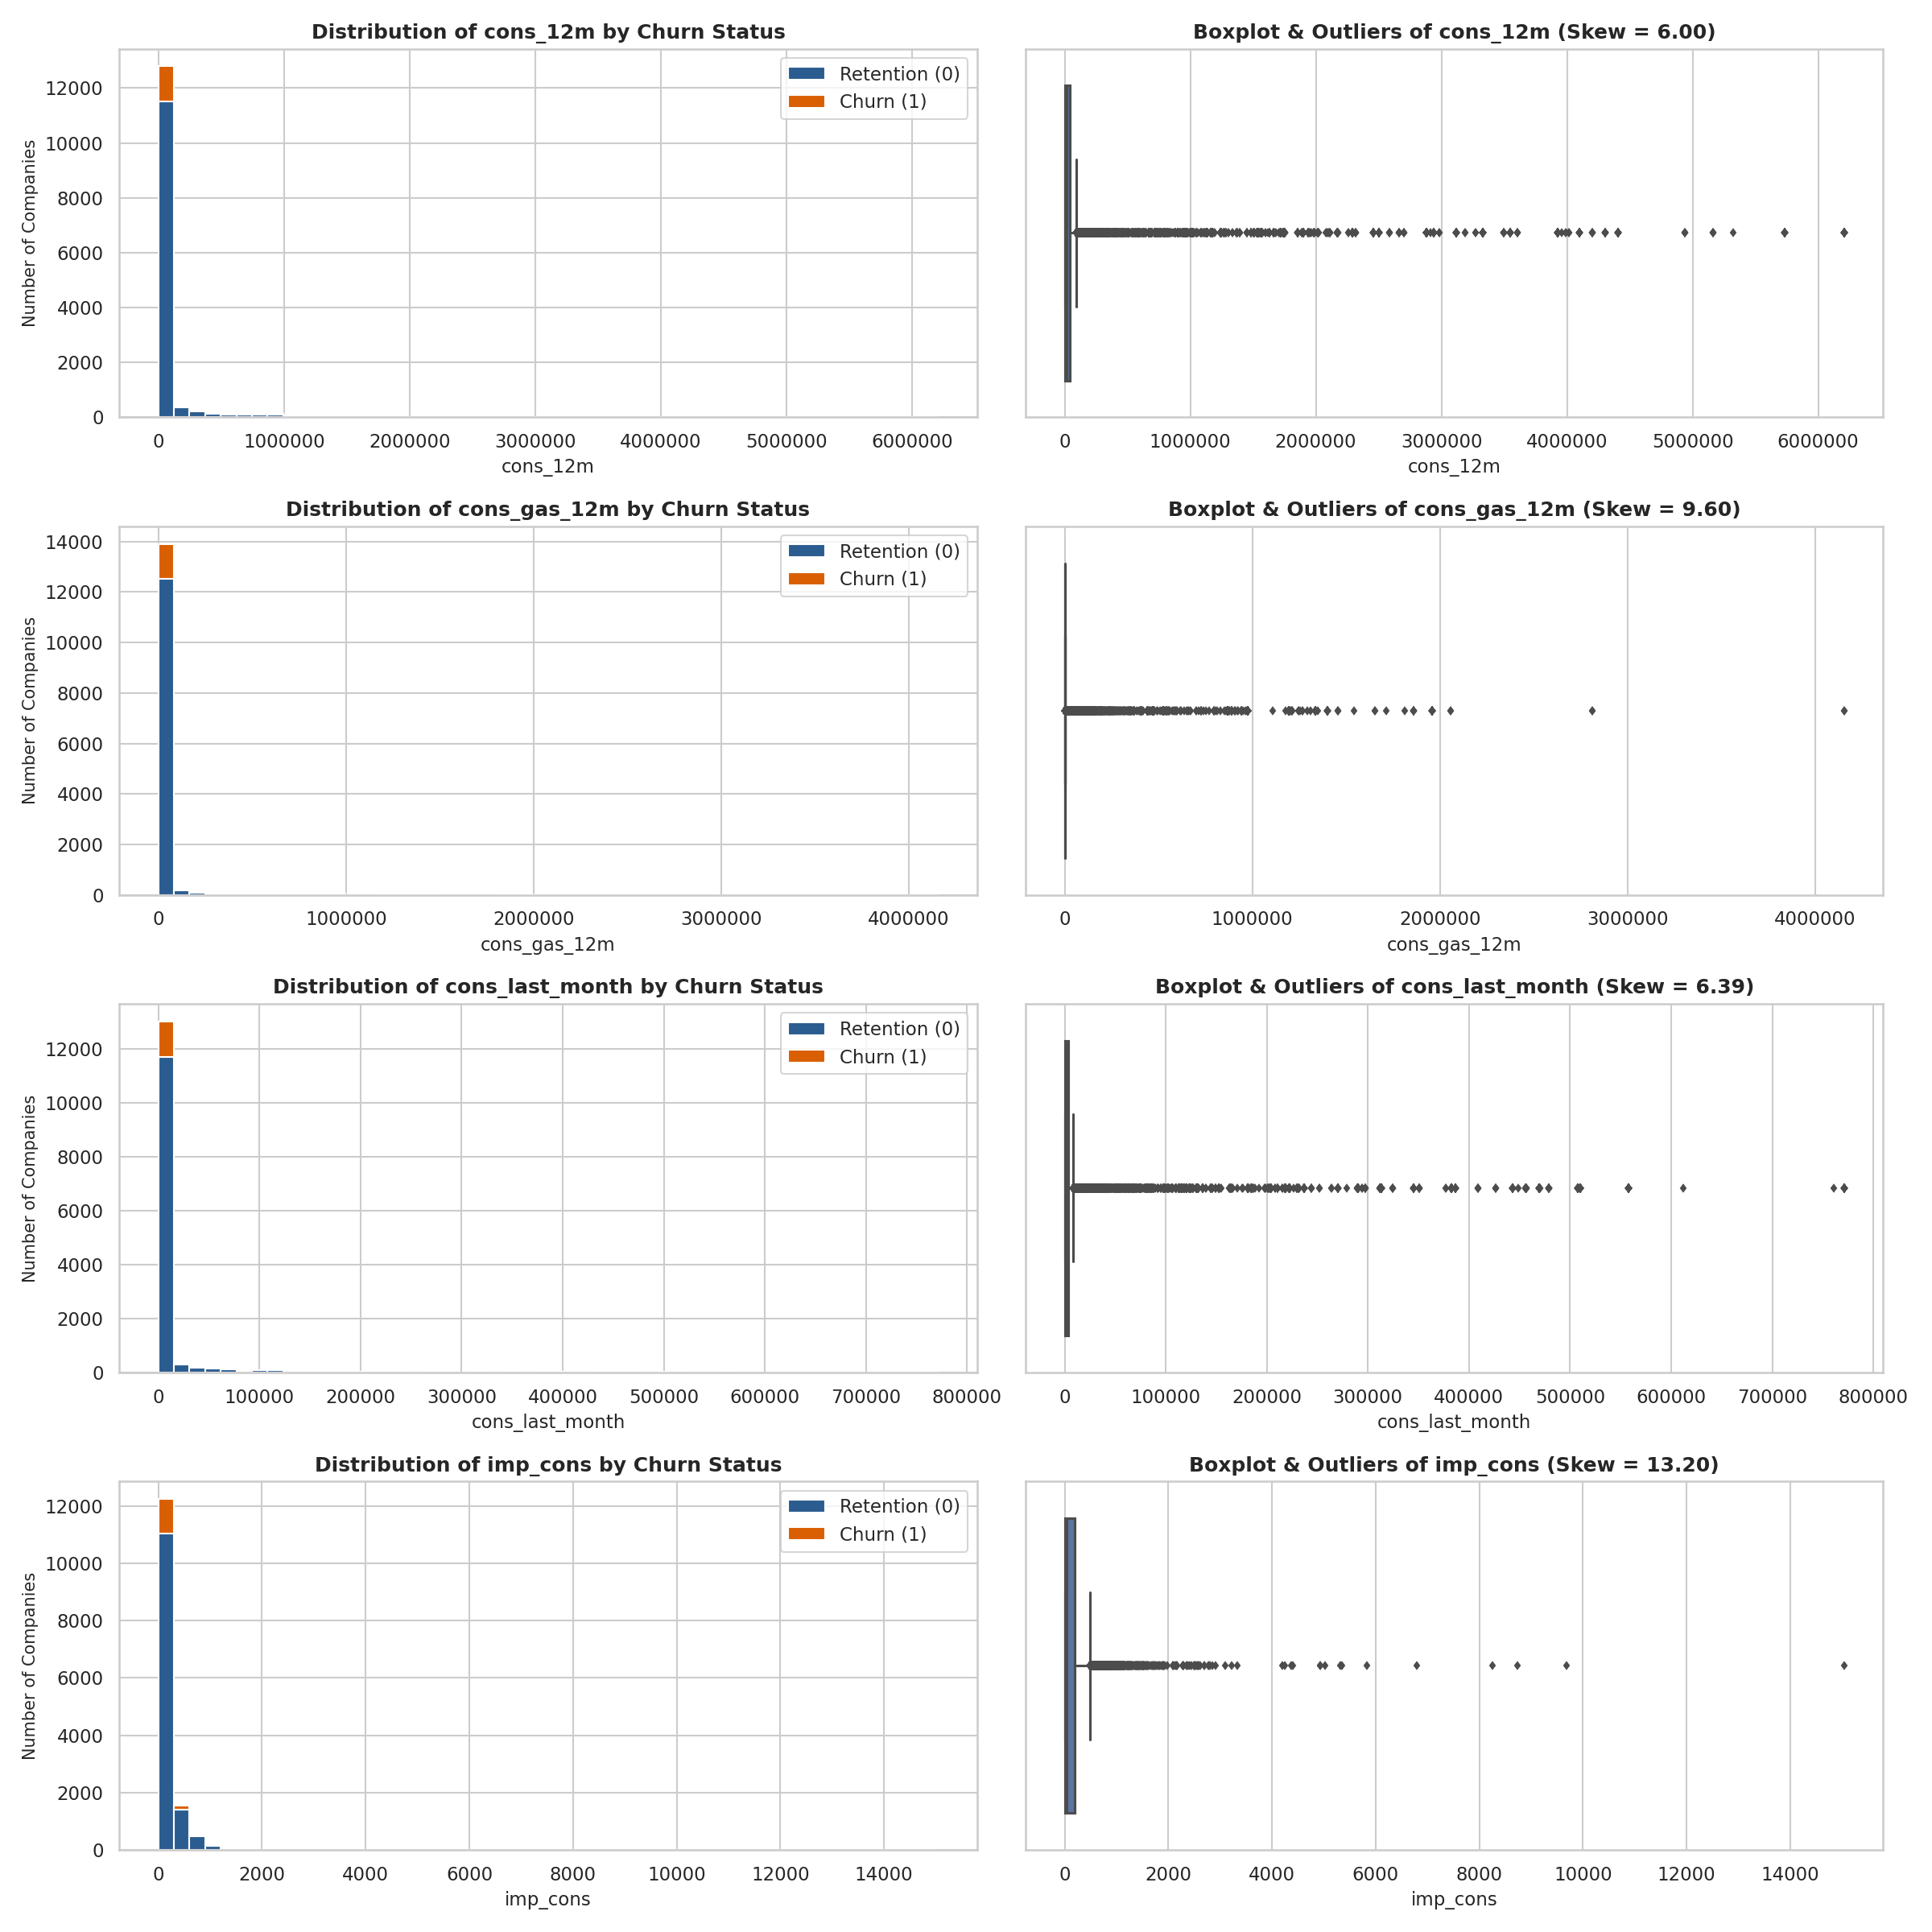

In [14]:
fig, axs = plt.subplots(nrows=4, ncols=2, figsize=(16, 16))
cons_cols = ['cons_12m', 'cons_gas_12m', 'cons_last_month', 'imp_cons']
for i, col in enumerate(cons_cols):
    plot_distribution(client_df, col, axs[i, 0], bins_=50)
    sns.boxplot(x=client_df[col], ax=axs[i, 1], color='#4c72b0')
    axs[i, 1].set_title(f'Boxplot of {col} (Skew = {client_df[col].skew():.2f})', fontweight='bold')
    axs[i, 1].ticklabel_format(style='plain', axis='x')
plt.tight_layout()
plt.show()

---
## 4. Forecasted Usage, Discounts, Margins & Subscribed Power
Next, we examine the distributions of forecasted consumption (`forecast_cons_12m`, `forecast_cons_year`), meter rent (`forecast_meter_rent_12m`), energy discounts (`forecast_discount_energy`), power margins (`margin_gross_pow_ele`, `margin_net_pow_ele`, `net_margin`), and subscribed power (`pow_max`).

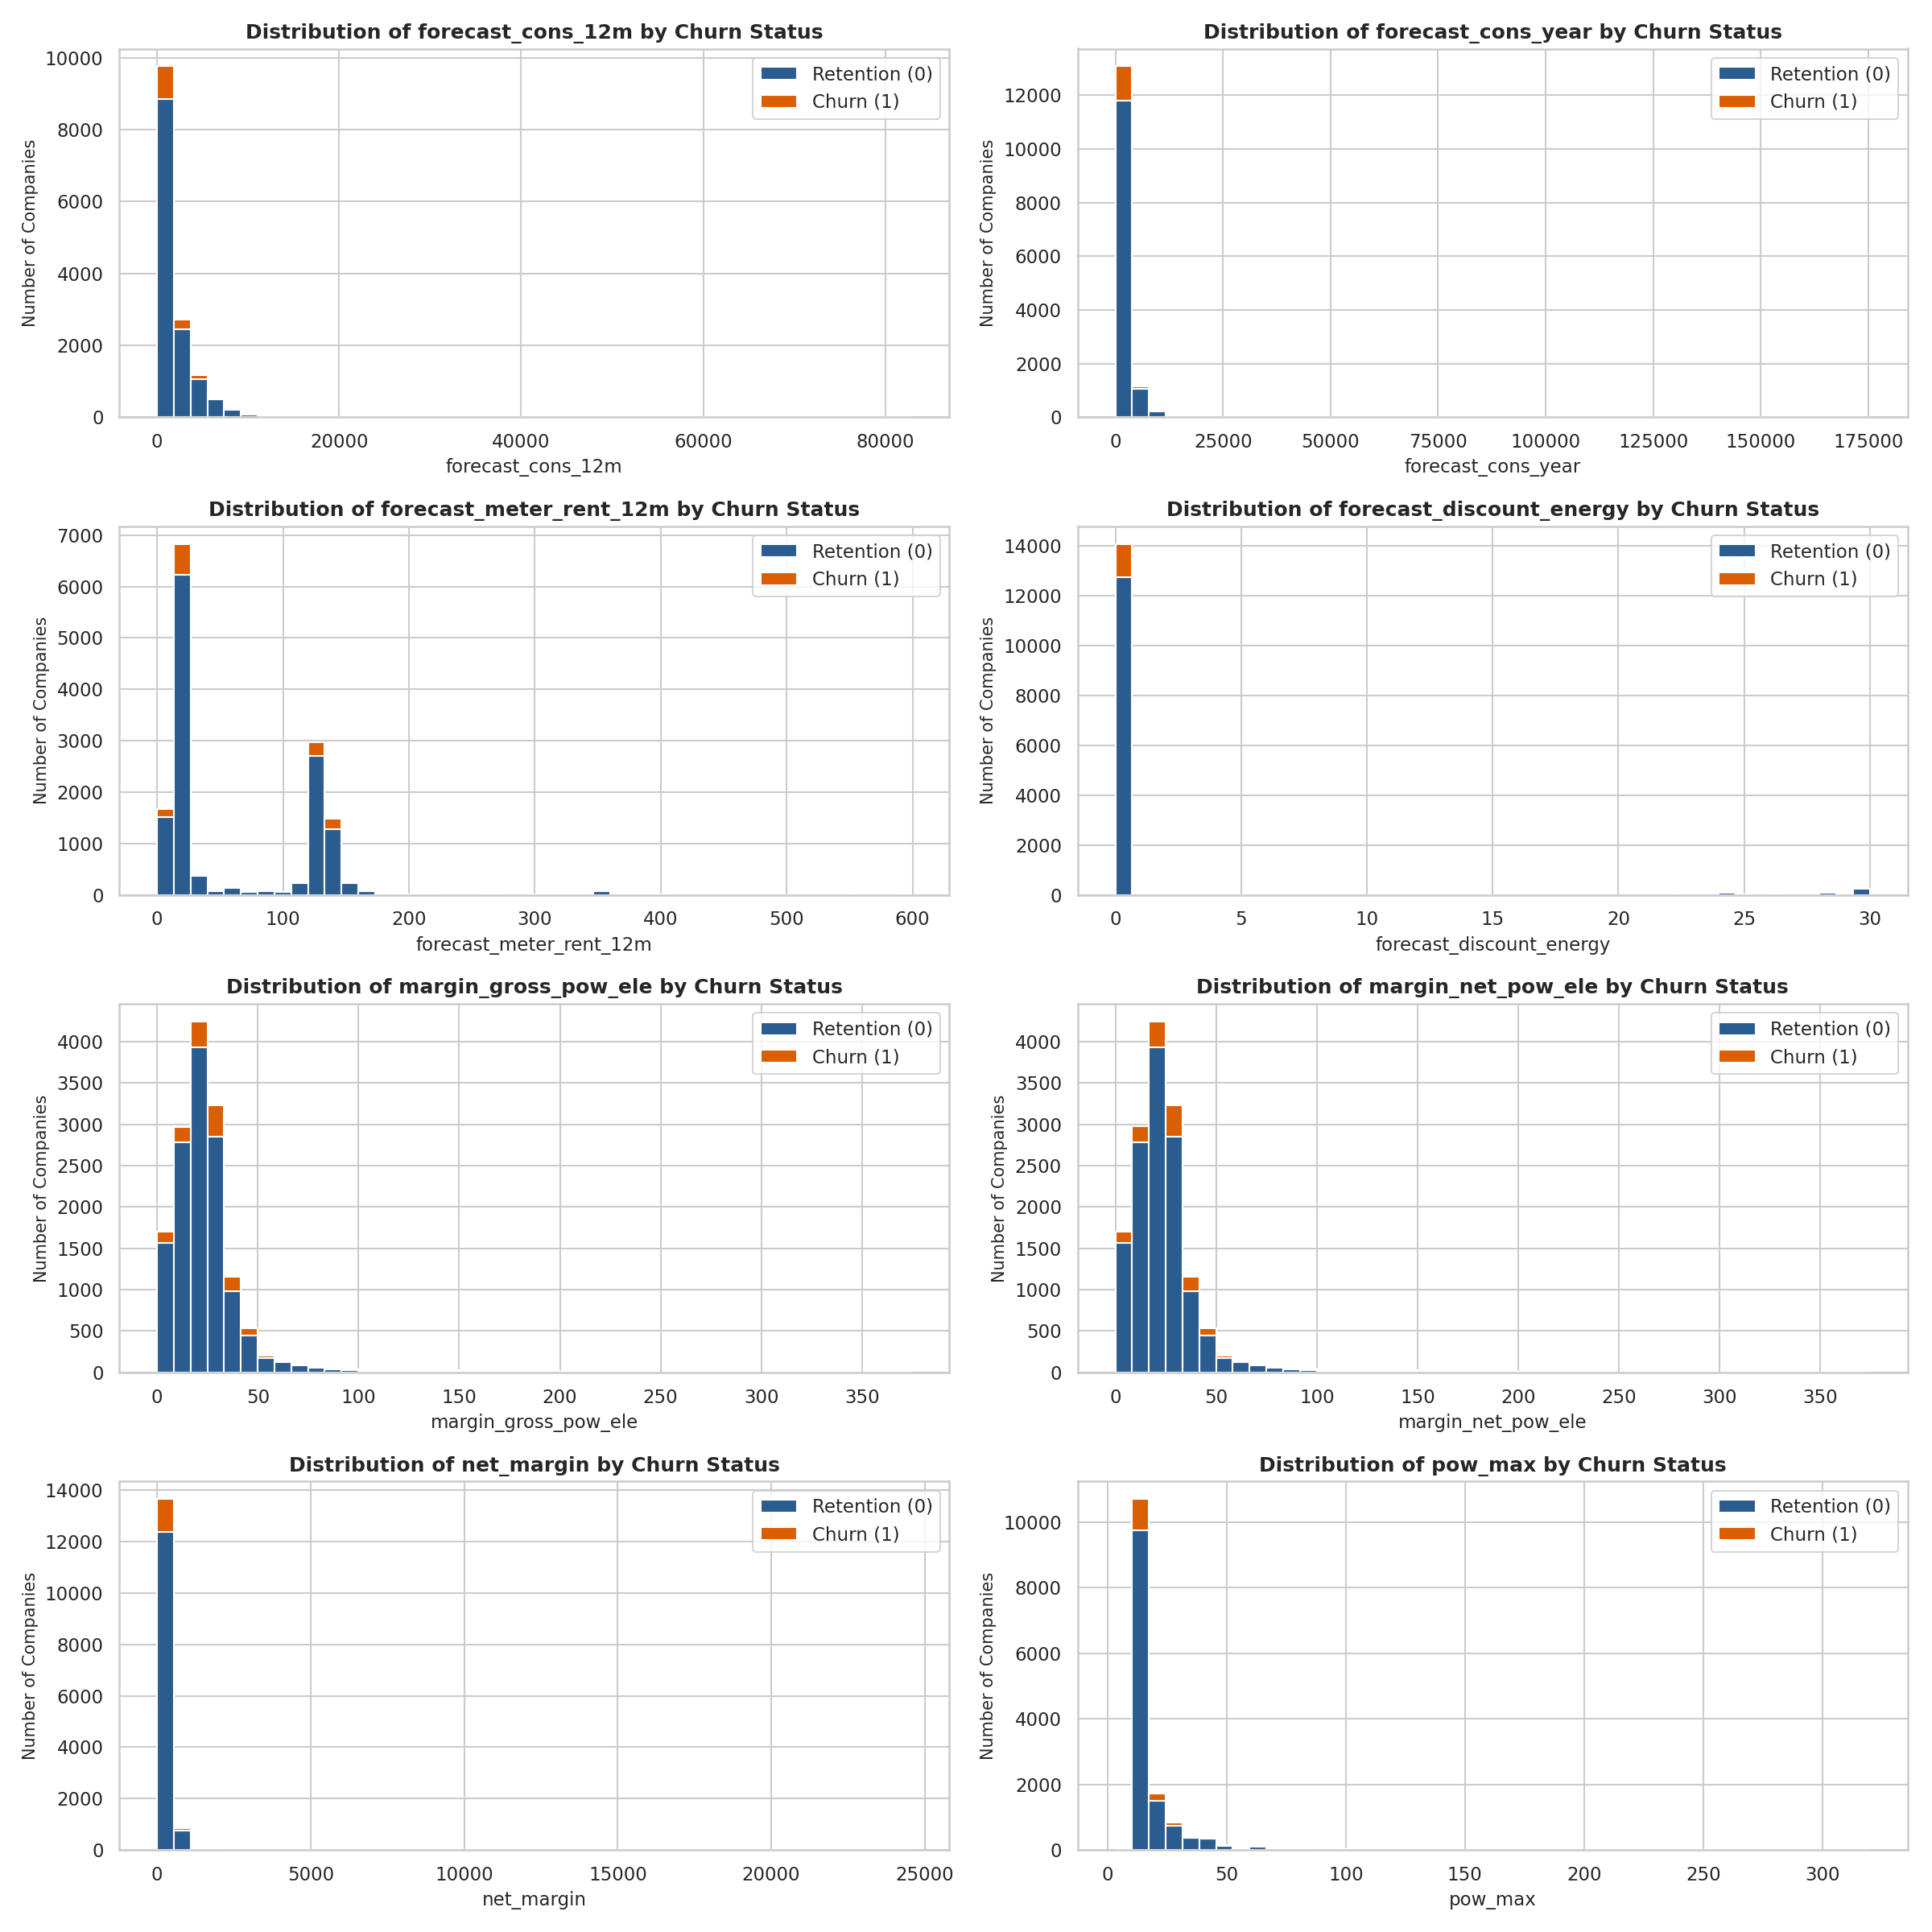

In [15]:
fig, axs = plt.subplots(nrows=4, ncols=2, figsize=(16, 16))
fm_cols = [
    'forecast_cons_12m', 'forecast_cons_year',
    'forecast_meter_rent_12m', 'forecast_discount_energy',
    'margin_gross_pow_ele', 'margin_net_pow_ele',
    'net_margin', 'pow_max'
]
for i, col in enumerate(fm_cols):
    r, c = divmod(i, 2)
    plot_distribution(client_df, col, axs[r, c], bins_=45)
plt.tight_layout()
plt.show()

---
## 5. Historical Pricing Data (`price_df`) Distributions
Finally, we inspect the 6 variable and fixed tariff columns across the 193,002 monthly price records in 2015.

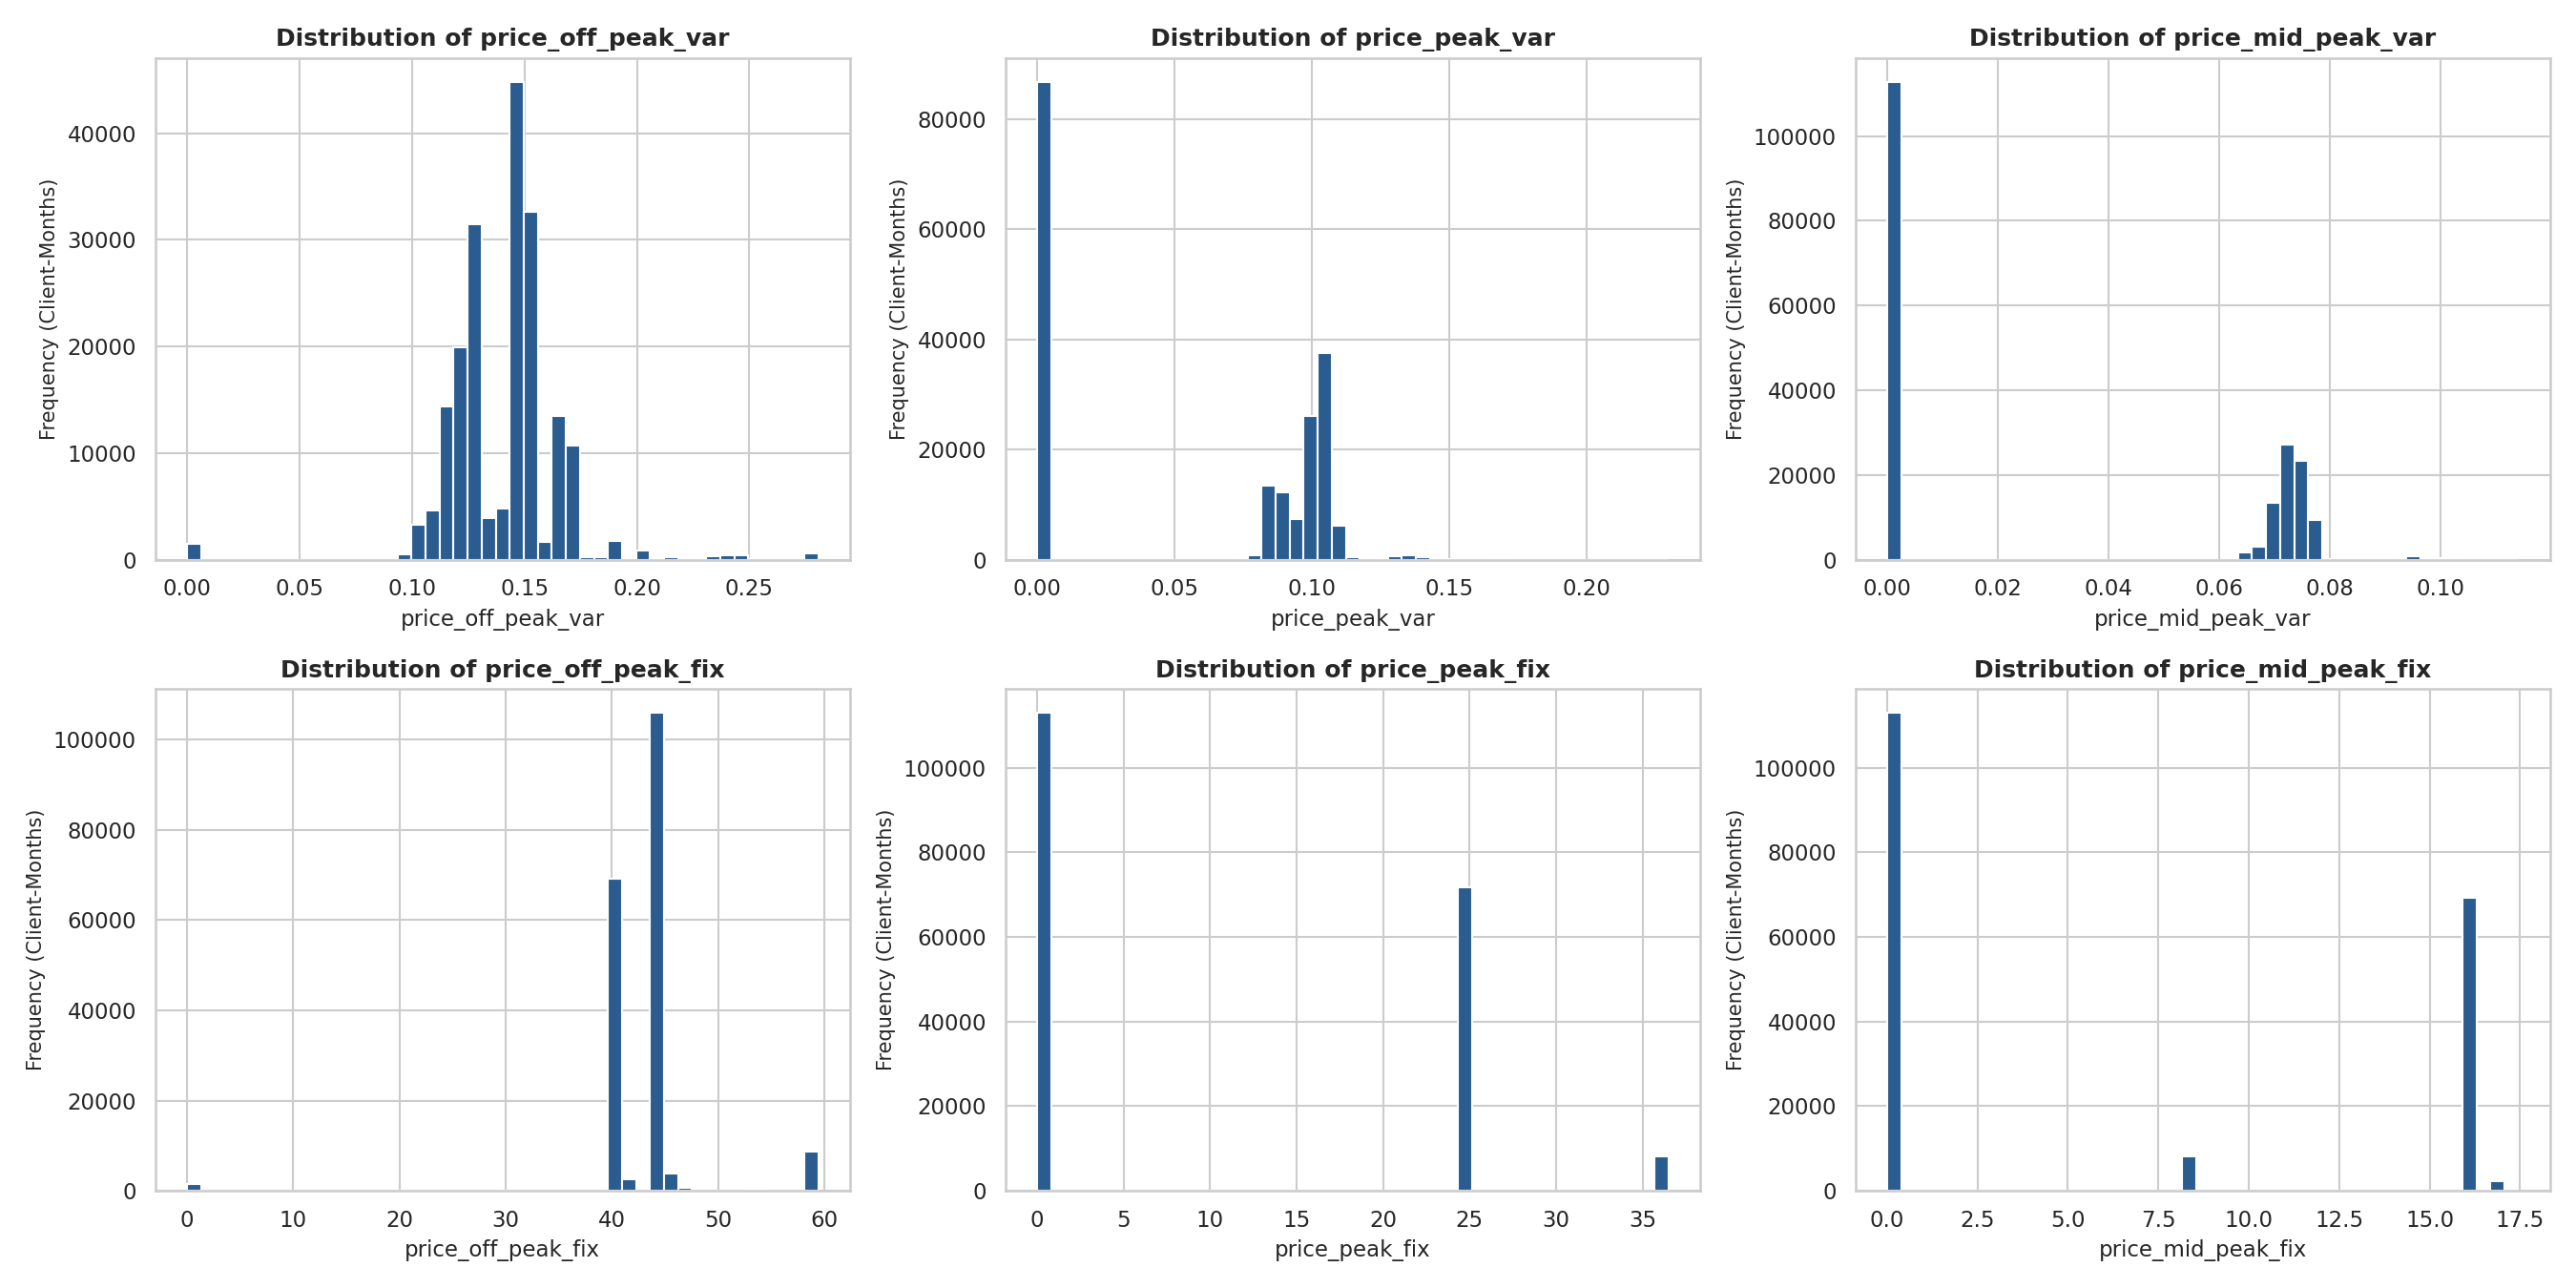

In [16]:
fig, axs = plt.subplots(nrows=2, ncols=3, figsize=(18, 9))
price_cols = [
    'price_off_peak_var', 'price_peak_var', 'price_mid_peak_var',
    'price_off_peak_fix', 'price_peak_fix', 'price_mid_peak_fix'
]
for i, col in enumerate(price_cols):
    r, c = divmod(i, 3)
    price_df[col].plot(kind='hist', bins=45, ax=axs[r, c], color='#2b5c8f', edgecolor='white')
    axs[r, c].set_title(f'Distribution of {col}', fontsize=12, fontweight='bold')
    axs[r, c].set_xlabel(col)
    axs[r, c].set_ylabel('Frequency (Client-Months)')
plt.tight_layout()
plt.show()